# Experiments 15,16,17
## Date: 24-11-2026

# 15.Matrix-Vector Multiplication using MapReduce

In [1]:
""" 
Matrix-vector multiplication x = M.v with MapReduce (Hadoop Streaming style). 
Input records : i<TAB>j<TAB>m_ij   (sparse matrix entries) 
  Hadoop  : -mapper "python exp15.py map" -reducer "python exp15.py reduce" 
            -files exp15.py,vector.txt 
""" 
  
import sys 
from itertools import groupby 
import numpy as np 
  
  
def load_vector(path="vector.txt"): 
    with open(path) as f: 
        return {int(j): float(v) for j, v in (line.split() for line in f)} 
  
  
def mapper(lines, v): 
    for line in lines: 
        i, j, m = line.split() 
        yield f"{int(i)}\t{float(m) * v[int(j)]}" 
  
  
def reducer(lines): 
    pairs = (l.rstrip("\n").split("\t") for l in lines) 
    for i, grp in groupby(pairs, key=lambda kv: int(kv[0])): 
        yield f"{i}\t{sum(float(x) for _, x in grp)}" 
  
  
if len(sys.argv) > 1 and sys.argv[1] in ("map", "reduce"): 
    if sys.argv[1] == "map": 
        out = mapper(sys.stdin, load_vector()) 
    else: 
        out = reducer(sys.stdin) 
    for o in out: 
        print(o) 
    sys.exit() 
  
# ---------------- Local simulation ---------------- 
# Link matrix of a 5-page website 
# (column j = page j shares its rank equally among the pages it links to) 
M = np.array( 
    [ 
        [0, 0.5, 0, 0, 1 / 3], 
        [1 / 3, 0, 0, 0.5, 0], 
        [1 / 3, 0, 0, 0.5, 1 / 3], 
        [1 / 3, 0, 1.0, 0, 1 / 3], 
        [0, 0.5, 0, 0, 0], 
    ] 
) 
v = np.array([0.2, 0.2, 0.2, 0.2, 0.2])  # current PageRank estimate 
  
entries = [ 
    f"{i}\t{j}\t{M[i, j]}" for i in range(5) for j in range(5) if M[i, j] != 0 
] 
with open("matrix.txt", "w") as f: 
    f.write("\n".join(entries)) 
with open("vector.txt", "w") as f: 
    f.write("\n".join(f"{j} {val}" for j, val in enumerate(v))) 
vec = load_vector() 
  
print("Matrix-Vector Multiplication using MapReduce (PageRank step)") 
print("=" * 60) 
print("Matrix M (5 x 5):") 
print(np.round(M, 3)) 
print("Vector v:", v) 
print(f"Non-zero entries stored as (i, j, m_ij): {len(entries)} of {M.size}") 
  
splits = [entries[:5], entries[5:]] 
print("\n--- MAP PHASE: emit (i, m_ij * v_j) ---") 
mapped = [] 
for s, chunk in enumerate(splits, 1): 
    out = list(mapper(chunk, vec)) 
    mapped += out 
    print(f"Mapper {s}:") 
    for rec, o in zip(chunk, out): 
        i, j, m = rec.split("\t") 
        print( 
            f"  ({i},{j}, {float(m):.3f}) -> key {o.split()[0]}, " 
            f"value {float(o.split()[1]):.4f}" 
        ) 
  
print("\n--- SHUFFLE AND SORT: group values by row i ---") 
shuffled = sorted(mapped, key=lambda s: int(s.split("\t")[0])) 
for i, grp in groupby(shuffled, key=lambda s: s.split("\t")[0]): 
    print(f"  row {i}: {[round(float(g.split()[1]), 4) for g in grp]}") 
  
print("\n--- REDUCE PHASE: x_i = sum of values ---") 
x = np.zeros(5) 
for r in reducer(shuffled): 
    i, val = r.split("\t") 
    x[int(i)] = float(val) 
    print(f"  x[{i}] = {float(val):.4f}") 
  
print("\nMapReduce result x  :", np.round(x, 4)) 
print("NumPy check   M @ v :", np.round(M @ v, 4)) 
print("Results match       :", np.allclose(x, M @ v)) 
  
print("\nRepeating the job (power iteration) gives PageRank:") 
r = v.copy() 
for it in range(1, 31): 
    r_new = M @ r 
    if it in (1, 2, 5, 30): 
        print(f"  iteration {it:>2}: {np.round(r_new, 4)}") 
    r = r_new 
print("Most important page:", int(np.argmax(r))) 

Matrix-Vector Multiplication using MapReduce (PageRank step)
Matrix M (5 x 5):
[[0.    0.5   0.    0.    0.333]
 [0.333 0.    0.    0.5   0.   ]
 [0.333 0.    0.    0.5   0.333]
 [0.333 0.    1.    0.    0.333]
 [0.    0.5   0.    0.    0.   ]]
Vector v: [0.2 0.2 0.2 0.2 0.2]
Non-zero entries stored as (i, j, m_ij): 11 of 25

--- MAP PHASE: emit (i, m_ij * v_j) ---
Mapper 1:
  (0,1, 0.500) -> key 0, value 0.1000
  (0,4, 0.333) -> key 0, value 0.0667
  (1,0, 0.333) -> key 1, value 0.0667
  (1,3, 0.500) -> key 1, value 0.1000
  (2,0, 0.333) -> key 2, value 0.0667
Mapper 2:
  (2,3, 0.500) -> key 2, value 0.1000
  (2,4, 0.333) -> key 2, value 0.0667
  (3,0, 0.333) -> key 3, value 0.0667
  (3,2, 1.000) -> key 3, value 0.2000
  (3,4, 0.333) -> key 3, value 0.0667
  (4,1, 0.500) -> key 4, value 0.1000

--- SHUFFLE AND SORT: group values by row i ---
  row 0: [0.1, 0.0667]
  row 1: [0.0667, 0.1]
  row 2: [0.0667, 0.1, 0.0667]
  row 3: [0.0667, 0.2, 0.0667]
  row 4: [0.1]

--- REDUCE PHASE: x_i

# 16.Relational Join and Aggregation using MapReduce

In [2]:
""" 
Two chained MapReduce jobs (Hadoop Streaming style): 
  Job 1 - reduce-side natural join of CUSTOMERS(cust_id, name, city) 
          and ORDERS(order_id, cust_id, amount) 
  Job 2 - grouping and aggregation: revenue, order count and maximum order per city 
""" 
  
from itertools import groupby 
  
customers = [ 
    "C1,Kavya,Chennai", 
    "C2,Ravi,Bengaluru", 
    "C3,Sana,Chennai", 
    "C4,Tarun,Hyderabad", 
    "C5,Uma,Bengaluru", 
] 
orders = [ 
    "O1,C1,2500", 
    "O2,C2,1800", 
    "O3,C1,700", 
    "O4,C3,4200", 
    "O5,C4,1500", 
    "O6,C2,3100", 
    "O7,C5,950", 
    "O8,C3,600", 
    "O9,C9,800", 
] 
  
  
# ---------------- Job 1: Join ---------------- 
def join_mapper(source, line): 
    f = line.split(",") 
    if source == "customers":  # tag each record with its relation 
        return f[0], ("C", f[1], f[2]) 
    return f[1], ("O", f[0], int(f[2])) 
  
  
def join_reducer(cust_id, values): 
    cust = [v for v in values if v[0] == "C"] 
    ords = [v for v in values if v[0] == "O"] 
    for c in cust:  # inner join: needs both sides 
        for o in ords: 
            yield cust_id, c[1], c[2], o[1], o[2] 
  
  
# ---------------- Job 2: Group by city ---------------- 
def agg_mapper(joined_row): 
    _, _, city, _, amount = joined_row 
    return city, amount 
  
  
def agg_reducer(city, amounts): 
    return city, sum(amounts), len(amounts), max(amounts) 
  
  
def shuffle(pairs): 
    pairs = sorted(pairs, key=lambda kv: kv[0]) 
    return [ 
        (k, [v for _, v in g]) for k, g in groupby(pairs, key=lambda kv: kv[0]) 
    ] 
  
  
print("Sales Analytics: Join and Aggregation using MapReduce") 
print("=" * 55) 
  
print("\nJOB 1 - MAP (key = cust_id, value tagged with relation):") 
mapped = [join_mapper("customers", l) for l in customers] + [ 
    join_mapper("orders", l) for l in orders 
] 
for k, v in mapped: 
    print(f"  {k} -> {v}") 
  
print("\nJOB 1 - SHUFFLE AND SORT:") 
groups = shuffle(mapped) 
for k, vals in groups: 
    print(f"  {k}: {vals}") 
  
print("\nJOB 1 - REDUCE (joined records):") 
joined = [row for k, vals in groups for row in join_reducer(k, vals)] 
print(f"  {'cust':<5}{'name':<7}{'city':<11}{'order':<7}amount") 
for row in joined: 
    print(f"  {row[0]:<5}{row[1]:<7}{row[2]:<11}{row[3]:<7}{row[4]}") 
print("  Note: order O9 (cust C9) has no matching customer and is dropped.") 
  
print("\nJOB 2 - MAP (key = city, value = amount):") 
mapped2 = [agg_mapper(r) for r in joined] 
print(" ", mapped2) 
  
print("\nJOB 2 - SHUFFLE AND SORT:") 
groups2 = shuffle(mapped2) 
for city, vals in groups2: 
    print(f"  {city}: {vals}") 
  
print("\nJOB 2 - REDUCE (aggregates per city):") 
print(f"  {'City':<11}{'Revenue':>8}{'Orders':>8}{'Max':>7}{'Avg':>9}") 
results = [agg_reducer(c, v) for c, v in groups2] 
for city, total, cnt, mx in sorted(results, key=lambda r: -r[1]): 
    print(f"  {city:<11}{total:>8}{cnt:>8}{mx:>7}{total / cnt:>9.2f}") 
print("\nGrand total revenue:", sum(r[1] for r in results)) 

Sales Analytics: Join and Aggregation using MapReduce

JOB 1 - MAP (key = cust_id, value tagged with relation):
  C1 -> ('C', 'Kavya', 'Chennai')
  C2 -> ('C', 'Ravi', 'Bengaluru')
  C3 -> ('C', 'Sana', 'Chennai')
  C4 -> ('C', 'Tarun', 'Hyderabad')
  C5 -> ('C', 'Uma', 'Bengaluru')
  C1 -> ('O', 'O1', 2500)
  C2 -> ('O', 'O2', 1800)
  C1 -> ('O', 'O3', 700)
  C3 -> ('O', 'O4', 4200)
  C4 -> ('O', 'O5', 1500)
  C2 -> ('O', 'O6', 3100)
  C5 -> ('O', 'O7', 950)
  C3 -> ('O', 'O8', 600)
  C9 -> ('O', 'O9', 800)

JOB 1 - SHUFFLE AND SORT:
  C1: [('C', 'Kavya', 'Chennai'), ('O', 'O1', 2500), ('O', 'O3', 700)]
  C2: [('C', 'Ravi', 'Bengaluru'), ('O', 'O2', 1800), ('O', 'O6', 3100)]
  C3: [('C', 'Sana', 'Chennai'), ('O', 'O4', 4200), ('O', 'O8', 600)]
  C4: [('C', 'Tarun', 'Hyderabad'), ('O', 'O5', 1500)]
  C5: [('C', 'Uma', 'Bengaluru'), ('O', 'O7', 950)]
  C9: [('O', 'O9', 800)]

JOB 1 - REDUCE (joined records):
  cust name   city       order  amount
  C1   Kavya  Chennai    O1     2500
  C

# 17.Line Plots, Formatting and Time-Series Trends

Monthly Sales Trend Analysis using Line Plots
            Electronics  Clothing  Groceries
2025-01-01        128.1      69.5      150.5
2025-02-01        128.4      66.4      153.3
2025-03-01        138.3      79.9      152.8
2025-04-01        141.6      89.8      151.0
2025-05-01        153.3     107.2      148.6
2025-06-01        136.0     121.8      152.6
...

Yearly totals (Rs. lakhs):
      Electronics  Clothing  Groceries
2025       1696.0    1159.6     1862.8
2026       2281.7    1410.5     1978.5

Peak Electronics month: Dec 2026 (207.0 lakhs)
Electronics trend line: sales = 125.62 + 3.49 * month_index


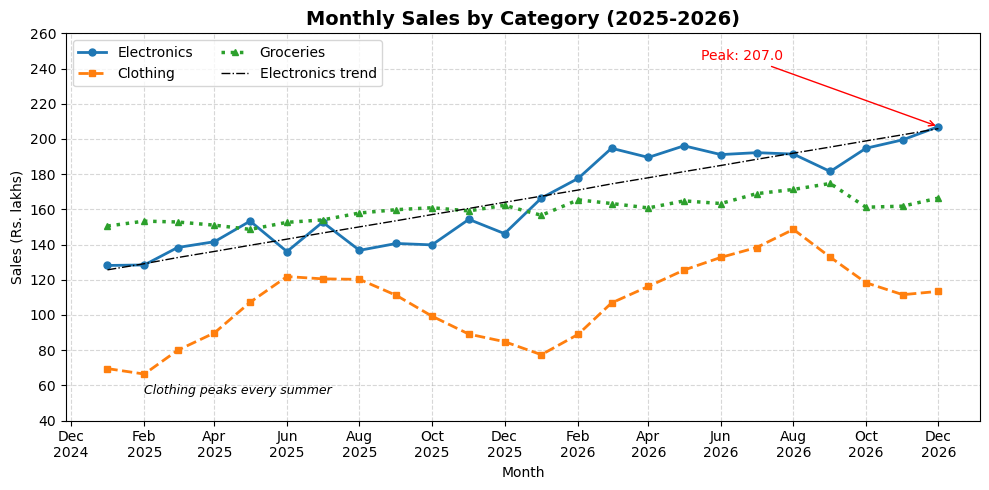

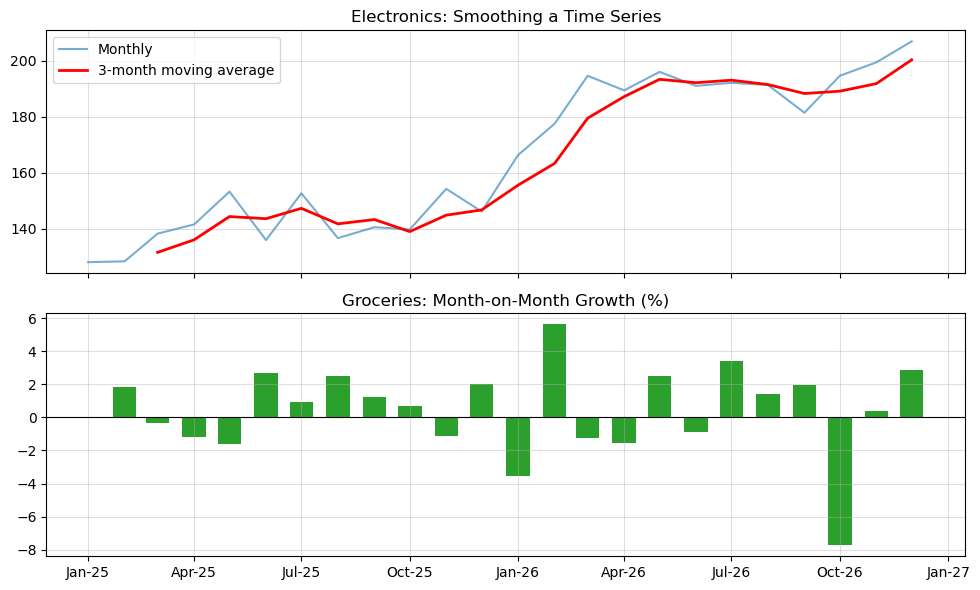


Saved figures: exp17_line.png, exp17_timeseries.png


In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import matplotlib.dates as mdates 
  
np.random.seed(1) 
months = pd.date_range("2025-01-01", periods=24, freq="MS") 
t = np.arange(24) 
sales = pd.DataFrame( 
    { 
        "Electronics": 120 
        + 4.0 * t 
        + 15 * np.sin(2 * np.pi * t / 12) 
        + np.random.normal(0, 5, 24), 
        "Clothing": 90 
        + 1.5 * t 
        + 25 * np.sin(2 * np.pi * (t - 3) / 12) 
        + np.random.normal(0, 5, 24), 
        "Groceries": 150 + 0.8 * t + np.random.normal(0, 4, 24), 
    }, 
    index=months, 
).round(1) 
  
print("Monthly Sales Trend Analysis using Line Plots") 
print("=" * 46) 
print(sales.head(6).to_string()) 
print("...") 
print("\nYearly totals (Rs. lakhs):") 
print(sales.groupby(sales.index.year).sum().round(1).to_string()) 
peak = sales["Electronics"].idxmax() 
print( 
    f"\nPeak Electronics month: {peak:%b %Y} ({sales['Electronics'].max()} lakhs)" 
) 
  
# Trend line for Electronics using least squares 
slope, intercept = np.polyfit(t, sales["Electronics"], 1) 
print( 
    f"Electronics trend line: sales = {intercept:.2f} + {slope:.2f} * month_index" 
) 
rolling = sales["Electronics"].rolling(3).mean() 
  
# ---------- Figure 1: formatted multi-line chart ---------- 
fig, ax = plt.subplots(figsize=(10, 5)) 
ax.plot( 
    sales.index, 
    sales["Electronics"], 
    color="tab:blue", 
    linestyle="-", 
    linewidth=2, 
    marker="o", 
    markersize=5, 
    label="Electronics", 
) 
ax.plot( 
    sales.index, 
    sales["Clothing"], 
    color="tab:orange", 
    linestyle="--", 
    linewidth=2, 
    marker="s", 
    markersize=5, 
    label="Clothing", 
) 
ax.plot( 
    sales.index, 
    sales["Groceries"], 
    color="tab:green", 
    linestyle=":", 
    linewidth=2.5, 
    marker="^", 
    markersize=5, 
    label="Groceries", 
) 
ax.plot( 
    sales.index, 
    intercept + slope * t, 
    color="black", 
    linestyle="-.", 
    linewidth=1, 
    label="Electronics trend", 
) 
  
ax.set_title( 
    "Monthly Sales by Category (2025-2026)", fontsize=14, fontweight="bold" 
) 
ax.set_xlabel("Month") 
ax.set_ylabel("Sales (Rs. lakhs)") 
ax.set_ylim(40, 260) 
ax.set_yticks(range(40, 261, 20)) 
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)) 
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y")) 
ax.grid(True, which="major", linestyle="--", alpha=0.5) 
ax.annotate( 
    f"Peak: {sales['Electronics'].max()}", 
    xy=(peak, sales["Electronics"].max()), 
    xytext=(peak - pd.Timedelta(days=200), 245), 
    arrowprops=dict(arrowstyle="->", color="red"), 
    color="red", 
) 
ax.text(months[1], 55, "Clothing peaks every summer", fontsize=9, style="italic") 
ax.legend(loc="upper left", ncol=2, frameon=True) 
plt.tight_layout() 
plt.savefig("exp17_line.png", dpi=150) 
  
# ---------- Figure 2: subplots with time-series smoothing ---------- 
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True) 
axes[0].plot(sales.index, sales["Electronics"], label="Monthly", alpha=0.6) 
axes[0].plot( 
    sales.index, rolling, color="red", linewidth=2, label="3-month moving average" 
) 
axes[0].set_title("Electronics: Smoothing a Time Series") 
axes[0].legend() 
axes[0].grid(alpha=0.4) 
growth = sales.pct_change().mul(100) 
axes[1].bar(sales.index, growth["Groceries"], width=20, color="tab:green") 
axes[1].axhline(0, color="black", linewidth=0.8) 
axes[1].set_title("Groceries: Month-on-Month Growth (%)") 
axes[1].grid(alpha=0.4) 
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b-%y")) 
plt.tight_layout() 
plt.savefig("exp17_timeseries.png", dpi=150) 
plt.show() 
print("\nSaved figures: exp17_line.png, exp17_timeseries.png") 